# Lecture 20, Predictor selection and nonlinear regression

> Which GCM variables should we use to predict local temperature or rainfall, and when does a neural network help?

A GCM gives us many variables: pressure, humidity, temperature at several heights. A station may have only 30 years of data. If we use too many predictors, the model starts to fit the random noise in those 30 years instead of the real signal, and it then predicts new years badly. So we must choose a few useful predictors. This lecture follows Chapter 5 of Lee and Singh (2019) and shows two ways to choose: **stepwise regression** and the **LASSO**. It then shows a model that can follow a curved relation, the **artificial neural network** (ANN).

By the end of this lecture you should be able to:

1. run stepwise regression and read its table of p-values;
2. compute a LASSO coefficient by hand for a given penalty and say which predictors survive as the penalty grows;
3. compute one forward pass and one training step of a small neural network by hand;
4. explain why a bigger network can fit the calibration years better and still do worse on new years.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

## Words you need

- **Standardising**: subtracting the mean and dividing by the standard deviation, so every variable is on the same scale. Example: temperatures 10, 12, 14 become $-1, 0, +1$.
- **Overfitting**: a model that matches the years it was fitted to very closely, noise included, and then predicts new years badly.
- **p-value**: the chance of seeing a relation this strong if the predictor were really useless. A small p-value (below 0.15 here) means the predictor probably helps.
- **Penalty and shrinkage**: a penalty is a cost added for large coefficients. It pulls ("shrinks") coefficients towards zero. Example: a coefficient of 0.84 shrinks to 0.34 when the penalty grows.
- **Validation set**: years kept out of the fitting and used only to test the model. Example: fit on 24 years, test on 6.
- **Activation function**: a smooth S-shaped curve that turns any number into a number between 0 and 1. Example: 0 becomes 0.5, a large positive number becomes nearly 1.
- **Gradient descent**: improving a model in small steps, each step moving the parameters in the direction that lowers the error fastest. The step size is the learning rate.

## Notation

The symbols follow Lee and Singh (2019), Sections 5.2 and 5.3. Predictors and predictand are standardised, so the intercept is $\beta_0=0$.

| Book symbol | Meaning in words | Code and spreadsheet |
|:--|:--|:--|
| $x_1,\dots,x_S$ | the $S$ candidate predictors | `x_1` ... `x_S`, columns of `X` |
| $x_{ji}$ | LASSO: predictor $i$ in year $j$ (row $j$, column $i$) | `X[j, i]` |
| $y_i$, $\hat y_i$ | observed and estimated predictand (temperature) of case $i$ | `y`, `y_hat` |
| $\beta_i$ | coefficient (weight) of predictor $i$ | `beta` |
| $\alpha_E,\ \alpha_M$ | p-value limits for entering and for removing a predictor | `alpha_E`, `alpha_M` |
| $\lambda$ | LASSO penalty: larger means more shrinkage | `lam` |
| $\rho_i,\ z_i$ | LASSO helper numbers for predictor $i$ (explained below) | `rho_i`, `z_i` |
| $\xi$ | tolerance: stop when no coefficient changes by more than this | `xi` |
| $\sigma(t)$ | sigmoid, the activation function | `sigma` |
| $w_{uv}$ | ANN weight from input $u$ to hidden node $v$ ($w_{0v}$ is a constant offset) | `w[u, v]` |
| $\alpha_v$ | ANN weight from hidden node $v$ to the output ($\alpha_0$ is an offset) | `alpha[v]` |
| $E$ | the error that training reduces (approximation square error) | `E` |
| $\zeta$ | learning rate, the step size | `zeta` |

The book uses $\alpha$ both for the p-value limits and for the ANN output weights; the context tells which is meant.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#666666"

def make_data(seed=13, n=30):
    """Recipe of the synthetic January temperature data (the CSV is exactly this output).
    x_2 and x_4 drive y (x_4 through a saturating tanh); x_3 is only weakly related to them; x_1 is noise."""
    rng = np.random.default_rng(seed)
    x1 = rng.standard_normal(n); x2 = rng.standard_normal(n); x4 = rng.standard_normal(n)
    x3 = 0.3 * x2 + 0.3 * x4 + 0.5 * rng.standard_normal(n)
    y = 0.6 * x2 + 1.0 * np.tanh(1.3 * x4) + 0.5 * rng.standard_normal(n)
    Z = np.c_[x1, x2, x3, x4, y]
    Z = (Z - Z.mean(0)) / Z.std(0, ddof=1)               # standardise
    df = pd.DataFrame(Z.round(3), columns=["x_1", "x_2", "x_3", "x_4", "y"])
    df.insert(0, "year", np.arange(1961, 1961 + n))
    return df

try:
    df = pd.read_csv("data/downscaling/lec20/lec20_data.csv")
except Exception:
    try:
        df = pd.read_csv("https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec20/lec20_data.csv")
    except Exception:
        df = make_data()
X = df[["x_1", "x_2", "x_3", "x_4"]].values      # feature matrix, X[j, i] = x_ji
y = df["y"].values
n, S = X.shape
print(df.head(4).to_string(index=False))
print(f"n = {n} years, S = {S} candidate predictors, all standardised")
print("correlation of each predictor with y:", np.round([np.corrcoef(X[:, i], y)[0, 1] for i in range(S)], 2))

 year    x_1    x_2    x_3    x_4      y
 1961  1.289  1.140  1.628 -0.311 -0.494
 1962 -2.911  0.053  0.515  0.907  0.520
 1963  0.545 -0.711  0.464 -0.342  0.315
 1964 -0.216 -1.277 -0.960 -0.364 -1.129
n = 30 years, S = 4 candidate predictors, all standardised
correlation of each predictor with y: [0.15 0.59 0.52 0.75]


**The data (synthetic).** $y$ is the standardised January mean of daily maximum temperature at a station for 1961 to 1990. The four predictors are standardised January variables from a reanalysis: $x_1$ sea-level pressure, $x_2$ specific humidity, $x_3$ 500 hPa geopotential height, $x_4$ 850 hPa temperature. In the synthetic truth only $x_2$ and $x_4$ affect $y$ ($x_4$ with a saturating curve); $x_1$ is pure noise and $x_3$ adds nothing beyond them.

# 5.2 Predictor selection

A GCM offers many candidate predictors, but unnecessary ones add noise to the estimate. We therefore want a small subset that still predicts well. The book treats two techniques: stepwise regression (SWR) and the LASSO.

**What this means for hydrology:** from many GCM variables we keep only those that carry information about local climate.

## 5.2.1 Stepwise regression

*In plain words:* build the model one predictor at a time, adding the one that helps most and dropping any that stop helping. "Helps" is judged by the p-value of the $t$ test of $H_0:\beta_i=0$: a small p-value means the coefficient is probably not zero, so the predictor probably carries information.

The procedure (book Section 5.2.1):

1. Set the significance levels to enter a predictor ($\alpha_E$) and to remove one ($\alpha_M$). The book uses $\alpha_E=\alpha_M=0.15$, more generous than 0.05, so that entering and removing are not too difficult.
2. Start with no predictor. (2.1) Fit each one-predictor model $Y=\beta_0+\beta_i x_i$. (2.2) Select the predictor with the smallest p-value among those below $\alpha_E$; if none is below $\alpha_E$, stop.
3. Suppose $x_3$ was chosen. (3.1) Fit each two-predictor model that contains $x_3$. (3.2) Add the predictor with the smallest p-value below $\alpha_E$. (3.3) If none qualifies, stop: the one-predictor model is final.
4. Step back: (4.1) after adding a second predictor, check whether the p-value of the first is now above $\alpha_M$, and if so remove it; (4.2) otherwise keep the model.
5. Continue until no predictor is added.

As in the book's Example 5.4, the data are first standardised so that variables on different scales are comparable and $\beta_0=0$. Each coefficient is tested with $T=(\hat\beta_i-0)/\mathrm{SE}$, the coefficient divided by its standard error (its uncertainty); a large $|T|$ gives a small p-value. The code below prints the coefficient and p-value of every candidate at every step, in the layout of the book's Table 5.10.

In [3]:
alpha_E = alpha_M = 0.15

def fit_t(cols):
    """Least squares of y on X[:, cols] (with intercept). Returns beta, SE, T, p-value of the predictors."""
    A = np.c_[np.ones(n), X[:, cols]]; k = len(cols)
    beta = np.linalg.solve(A.T @ A, A.T @ y)
    s2 = np.sum((y - A @ beta) ** 2) / (n - k - 1)
    SE = np.sqrt(np.diag(s2 * np.linalg.inv(A.T @ A)))
    T = beta / SE
    p = 2 * stats.t.sf(np.abs(T), n - k - 1)
    return beta[1:], SE[1:], T[1:], p[1:]

def stepwise():
    model = []
    while True:
        best = None
        print("model so far: x_" + ", x_".join(str(i + 1) for i in model) if model else "model so far: no predictor")
        for i in range(S):
            if i in model:
                continue
            beta, SE, T, p = fit_t(model + [i])
            print(f"   try x_{i+1}:  beta_{i+1} = {beta[-1]:+.3f}  SE = {SE[-1]:.3f}  T = {T[-1]:+.2f}  p = {p[-1]:.2g}")
            if p[-1] < alpha_E and (best is None or p[-1] < best[1]):
                best = (i, p[-1])
        if best is None:
            print("   no p-value below alpha_E: stop"); return model
        model.append(best[0]); print(f"   enter x_{best[0]+1}")
        p = fit_t(model)[3]
        for i, pi in zip(model, p):
            if pi > alpha_M:
                model.remove(i); print(f"   p-value of x_{i+1} is now {pi:.3f} > alpha_M: remove x_{i+1}")
                break

final = stepwise()
beta = fit_t(final)[0]
print("\nfinal model: y = " + " ".join(f"{b:+.3f} x_{i+1}" for b, i in zip(beta, final)))

model so far: no predictor
   try x_1:  beta_1 = +0.146  SE = 0.187  T = +0.78  p = 0.44
   try x_2:  beta_2 = +0.590  SE = 0.153  T = +3.86  p = 0.00061
   try x_3:  beta_3 = +0.522  SE = 0.161  T = +3.24  p = 0.0031
   try x_4:  beta_4 = +0.747  SE = 0.126  T = +5.94  p = 2.1e-06
   enter x_4
model so far: x_4
   try x_1:  beta_1 = +0.185  SE = 0.123  T = +1.50  p = 0.15
   try x_2:  beta_2 = +0.452  SE = 0.098  T = +4.62  p = 8.4e-05
   try x_3:  beta_3 = +0.207  SE = 0.141  T = +1.46  p = 0.15
   enter x_2
model so far: x_4, x_2
   try x_1:  beta_1 = +0.031  SE = 0.104  T = +0.30  p = 0.77
   try x_3:  beta_3 = +0.035  SE = 0.119  T = +0.29  p = 0.77
   no p-value below alpha_E: stop

final model: y = +0.651 x_4 +0.452 x_2


Stepwise regression gives a small model, but it is greedy: the order of entry matters and the p-values are slightly optimistic because we searched for them.

## 5.2.2 Least absolute shrinkage and selection operator (LASSO)

*In plain words:* ordinary regression only tries to make the errors small, so given many predictors it uses them all and starts to fit noise. The LASSO adds a *penalty* for large coefficients, so a predictor is kept only if it reduces the error by more than it costs in penalty. Useless predictors end with a coefficient of exactly zero.

**Cost function.** Ordinary regression minimises the sum of squared errors (Eq. 5.17), $\text{Total cost}=\sum_{i=1}^{n}(y_i-\hat y_i)^2$. With many predictors this gives a model that fits the fitting years well (low bias) but predicts new years badly (high variance). *Regularisation* adds a penalty $R(\beta)$ with a tuning parameter $\lambda$ (Eq. 5.18). The LASSO uses the $L_1$ norm, the sum of the sizes of the coefficients, $R(\beta)=\lVert\beta\rVert_1=\sum_{j=1}^{S}|\beta_j|$ (Eq. 5.19), so

$$\text{Total cost}=\sum_{i=1}^{n}(y_i-\hat y_i)^2+\lambda\sum_{j=1}^{S}|\beta_j|\qquad(5.20)$$

The penalty keeps the coefficients from growing and can set some exactly to zero. As $\lambda$ increases, more coefficients become zero, which is the predictor selection.

**Choosing $\lambda$ for a wanted number $p$ of predictors.** (1) Split the data at random into a training set and a validation set (90/10 or 80/20 per cent). (2) Choose $m$ values of $\lambda$, from small to large. (3) Fit the LASSO to the training set for each $\lambda$. (4) Keep the fits that have exactly $p$ nonzero coefficients. (5) Among them choose the one with the smallest error on the validation set. When there are few data, the book uses $K$-fold cross-validation instead: split the data into $K$ parts, use each part once as validation and the rest for training, and average the validation errors (Eqs. 5.21 and 5.22); we do not use it here.

**Coordinate descent.** Because $|\beta|$ has no slope at zero, there is no closed formula. The book changes one coefficient $\beta_i$ at a time with the others fixed. Write the cost as the squared-error part SSE plus the penalty (Eq. 5.23). With $z_i=\sum_{j=1}^{n}x_{ji}^2$ (the size of predictor $i$) and

$$\rho_i=\sum_{j=1}^{n}x_{ji}\Big(y_j-\sum_{k\ne i}x_{jk}\beta_k\Big)=x_i^{T}(y-\hat y+\beta_i x_i)$$

(how strongly predictor $i$ is related to what the other predictors have not explained), the slope of SSE with respect to $\beta_i$ is $-2\rho_i+2z_i\beta_i$ (Eqs. 5.24 and 5.25). The slope of the penalty $\lambda|\beta_i|$ is $+\lambda$ for $\beta_i>0$, $-\lambda$ for $\beta_i<0$, and anything between $-\lambda$ and $\lambda$ at $\beta_i=0$ (Eq. 5.26). Adding the two slopes (Eq. 5.27) and setting the total to zero gives the **soft threshold** (Eq. 5.28):

- if $\rho_i<-\lambda/2$: $\hat\beta_i=(\rho_i+\lambda/2)/z_i$;
- if $-\lambda/2\le\rho_i\le\lambda/2$: $\hat\beta_i=0$;
- if $\rho_i>\lambda/2$: $\hat\beta_i=(\rho_i-\lambda/2)/z_i$.

In words: the penalty "eats" $\lambda/2$ of the relationship strength $\rho_i$; if nothing is left, the predictor is switched off.

**Algorithm.** (1) Make the feature matrix of standardised predictors and the response vector (one value per case). (2) Start with $\beta=0$. (3) For $i=1,\dots,S$: compute $\hat y=X\beta$, $\rho_i$ and $z_i$; get the regularised $\beta_i$ from Eq. (5.28); compute the change $c_i=\beta_i^{\text{(regularised)}}-\beta_i$ and update $\beta_i$. (4) Stop if $\max_i|c_i|<\xi$ (the book takes $\xi=10^{-4}$); otherwise repeat step 3.

**What this means for hydrology:** the data decide which GCM variables to switch off, and the validation years tell us how much shrinkage still predicts well.

### Worked example (by hand): the first coordinate-descent update

**Problem.** As in the first step of the book's Example 5.5, but with one predictor and six years, standardised roughly (centred, about unit spread). Find the coefficient $\hat\beta_1$ for $\lambda=1,\ 6,\ 12$.

| year $j$ | 1 | 2 | 3 | 4 | 5 | 6 |
|:--|--:|--:|--:|--:|--:|--:|
| $x_{j1}$ | -1.5 | -0.8 | -0.3 | 0.3 | 0.8 | 1.5 |
| $y_j$ | -1.2 | -0.9 | -0.1 | 0.3 | 0.7 | 1.2 |

**Step 1, initial parameter.** Start from $\beta_1=0$, so the estimate is $\hat y_j=0$ (nothing explained yet).

**Step 2, $z_1$** (size of the predictor). $z_1=\sum x_{j1}^2=2.25+0.64+0.09+0.09+0.64+2.25=5.96$.

**Step 3, $\rho_1$** (strength of the relation). With $\hat y=0$ and $\beta_1=0$: $\rho_1=\sum x_{j1}y_j=1.80+0.72+0.03+0.09+0.56+1.80=5.00$. With no penalty the slope would be $\rho_1/z_1=5.00/5.96=0.8389$.

**Step 4, regularise with Eq. (5.28)** (compare $\rho_1=5.00$ with $\lambda/2$):

- $\lambda=1$: $\lambda/2=0.5<\rho_1$, so $\hat\beta_1=(5.00-0.5)/5.96=0.7550$. A small shrink.
- $\lambda=6$: $\lambda/2=3<\rho_1$, so $\hat\beta_1=(5.00-3)/5.96=0.3356$. A bigger shrink.
- $\lambda=12$: $\lambda/2=6>\rho_1$, so $\hat\beta_1=0$. The penalty wins and the predictor is switched off.

**Step 5, change** (as in step 3.3 of the algorithm). For $\lambda=6$, $c_1=0.3356-0=0.3356$. With one predictor there is nothing else to update, so the next sweep gives $c_1=0<\xi$ and the algorithm stops.

**Step 6, check that this is the minimum** for $\lambda=6$. The cost is $\sum y_j^2-2\beta\rho_1+\beta^2z_1+6|\beta|$ with $\sum y_j^2=4.28$. At $\beta=0$ it is 4.2800; at $\beta=0.8389$ it is 5.1189; at $\beta=0.3356$ it is $4.28-2(0.3356)(5.00)+(0.3356)^2(5.96)+6(0.3356)=3.6089$, the lowest.

**Answer.** $\hat\beta_1=0.7550,\ 0.3356,\ 0$ for $\lambda=1,6,12$: a larger penalty shrinks the slope and finally removes the predictor.

In [4]:
# The same numbers by code (the spreadsheet sheet LASSO_1D has the same problem)
x_h = np.array([-1.5, -0.8, -0.3, 0.3, 0.8, 1.5]); y_h = np.array([-1.2, -0.9, -0.1, 0.3, 0.7, 1.2])

def soft_threshold(rho_i, z_i, lam):
    """Eq. (5.28)."""
    if rho_i < -lam / 2: return (rho_i + lam / 2) / z_i
    if rho_i > lam / 2:  return (rho_i - lam / 2) / z_i
    return 0.0

z_1 = x_h @ x_h; rho_1 = x_h @ y_h                      # beta_1 = 0, so y_hat = 0
print(f"z_1 = {z_1:.4f}   rho_1 = {rho_1:.4f}   least squares slope = {rho_1 / z_1:.4f}")
for lam in (1, 6, 12):
    b = soft_threshold(rho_1, z_1, lam)
    cost = np.sum((y_h - b * x_h) ** 2) + lam * abs(b)  # Eq. (5.20)
    print(f"lambda = {lam:2d}:  beta_1 = {b:.4f}   total cost = {cost:.4f}")

z_1 = 5.9600   rho_1 = 5.0000   least squares slope = 0.8389
lambda =  1:  beta_1 = 0.7550   total cost = 0.8823
lambda =  6:  beta_1 = 0.3356   total cost = 3.6089
lambda = 12:  beta_1 = 0.0000   total cost = 4.2800


**Example 5.5 on our data.** The book's first approach, step by step: (1) standardise the data (done) and shuffle the years at random; the first 24 are the training set, the other 6 the validation set. (2) Take 100 values of $\lambda$. (3) Build the feature matrix and response vector from the training set. (4) For each $\lambda$, fit by coordinate descent from $\beta=[0,0,0,0]$ with $\xi=10^{-4}$. (5) Collect the $\hat\beta$ for all $\lambda$ (the book's Table 5.13). (6) Keep the fits with exactly two nonzero coefficients. (7) Compute their validation errors (Table 5.14). (8) Choose the smallest. The book also shows that, without fixing $p$, one can simply take the $\lambda$ with the smallest validation error. Our $\lambda$ grid runs to 60 instead of the book's 4, because $\lambda$ must be compared with $\rho_i$, which grows with the number of years.

fits with exactly 2 nonzero coefficients: 43 of 100
chosen: lambda = 10.305, beta_hat = [0.    0.328 0.    0.478], validation error = 0.529
smallest validation error over all lambda: lambda = 10.305, beta_hat = [0.    0.328 0.    0.478]


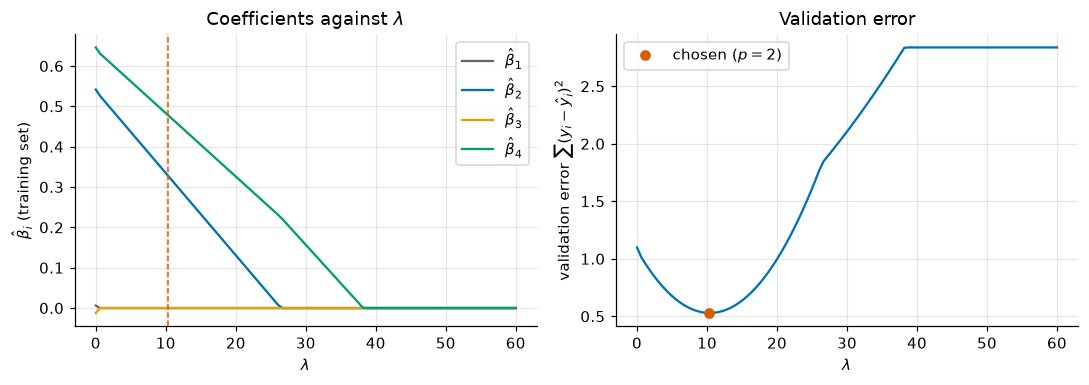

In [5]:
def lasso_cd(X, y, lam, xi=1e-4):
    """Coordinate descent (book Section 5.2.2): sweep i = 1..S, update beta_i by Eq. (5.28)."""
    beta = np.zeros(X.shape[1])
    while True:
        c_max = 0.0
        for i in range(X.shape[1]):
            y_hat = X @ beta
            rho_i = X[:, i] @ (y - y_hat + beta[i] * X[:, i])
            z_i = X[:, i] @ X[:, i]
            beta_new = soft_threshold(rho_i, z_i, lam)
            c_max = max(c_max, abs(beta_new - beta[i])); beta[i] = beta_new
        if c_max < xi:
            return beta

idx = np.random.default_rng(1).permutation(n)
train, valid = idx[:24], idx[24:]
lams = np.linspace(0.002, 60, 100)
B = np.array([lasso_cd(X[train], y[train], lam) for lam in lams])           # 100 x S
val_err = np.array([np.sum((y[valid] - X[valid] @ b) ** 2) for b in B])
n_nonzero = (B != 0).sum(1)

p_wanted = 2
ok = n_nonzero == p_wanted
k_best = np.where(ok)[0][np.argmin(val_err[ok])]
print(f"fits with exactly {p_wanted} nonzero coefficients: {ok.sum()} of {len(lams)}")
print(f"chosen: lambda = {lams[k_best]:.3f}, beta_hat = {np.round(B[k_best], 3)}, validation error = {val_err[k_best]:.3f}")
print(f"smallest validation error over all lambda: lambda = {lams[val_err.argmin()]:.3f}, beta_hat = {np.round(B[val_err.argmin()], 3)}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for i, col in enumerate([GREY, BLUE, ORANGE, GREEN]):
    ax[0].plot(lams, B[:, i], color=col, label=f"$\\hat\\beta_{i+1}$")
ax[0].axvline(lams[k_best], color=RED, ls="--", lw=1)
ax[0].set(xlabel="$\\lambda$", ylabel="$\\hat\\beta_i$ (training set)", title="Coefficients against $\\lambda$"); ax[0].legend()
ax[1].plot(lams, val_err, color=BLUE)
ax[1].plot(lams[k_best], val_err[k_best], "o", color=RED, label=f"chosen ($p={p_wanted}$)")
ax[1].set(xlabel="$\\lambda$", ylabel="validation error $\\sum(y_i-\\hat y_i)^2$", title="Validation error"); ax[1].legend()
plt.tight_layout(); plt.show()

Reading the figure: the noise predictor $x_1$ and the weak predictor $x_3$ drop to exactly zero at small $\lambda$. The two real predictors survive much longer and shrink slowly; $x_2$ reaches zero first, then $x_4$. The validation error is highest when the penalty switches everything off, falls once the useless predictors are removed, and rises again when the useful coefficients are shrunk too much. The best $\lambda$ lies in between, and the fit with two nonzero coefficients is also the overall best.

**What this means for hydrology:** the selected pair, humidity and 850 hPa temperature, is what we would give to the downscaling regression of Lecture 19.

# 5.3 Nonlinear regression modeling

*In plain words:* a regression with straight lines cannot follow a bend or a saturation, such as temperature rising quickly with humidity at first and then levelling off. The artificial neural network can.

**What this means for hydrology:** it lets a downscaling model follow curved links between GCM variables and local climate.

## 5.3.1 Artificial neural network (ANN)

**Structure.** An ANN has an input layer, a hidden layer and an output layer, each made of nodes (neurons). Data enter the input nodes, pass to the hidden nodes and end at the output node. The book's Figure 5.8 has two input nodes, three hidden nodes and one output node. Between the layers the data are multiplied by weights and passed through an **activation function**, a smooth curve that turns any number into a bounded one. Two examples are the sigmoid and the hyperbolic tangent (Eqs. 5.29 and 5.30): $\sigma(t)=(1+e^{-t})^{-1}$ and $\tanh(t)=(e^{t}-e^{-t})/(e^{t}+e^{-t})$. For example $\sigma(0)=0.5$, and $\sigma(t)\to1$ for large $t$.

**Forward calculation.** With a sigmoid between the input and hidden layers and a linear function between the hidden and output layers, the network of Figure 5.8 is the function (Eq. 5.31)

$$\hat y_i=\alpha_0+\sum_{v=1}^{H}\alpha_v\,\sigma\big(w_{0v}+w_{1v}x_{i,1}+w_{2v}x_{i,2}\big),\qquad H=3 .$$

Read it from the inside out: each hidden node $v$ forms a weighted sum of the inputs ($w_{uv}$ are weights, $w_{0v}$ an offset or bias) and passes it through $\sigma$; the output adds the hidden values with weights $\alpha_v$ and an offset $\alpha_0$.

**Training, validation and testing.** The data are split into three parts: (1) estimate the weights on the training data; (2) check the architecture, for example the number of hidden nodes, on the validation data; (3) test the final network on the test data. The book omits the test part when the record is short, and so do we.

**Error function.** The weights are chosen to minimise the approximation square error over the $T$ training cases (Eq. 5.32),

$$E=\frac12\sum_{i=1}^{T}(y_i-\hat y_i)^2,$$

and the minimum is where $\partial E/\partial\theta_p=0$ for all $P$ parameters $\theta_p$ (Eq. 5.33).

**Training rule.** Back-propagation moves the parameter vector $\theta$ along the negative gradient of $E$, that is, in the direction in which $E$ decreases fastest (Eq. 5.34):

$$\theta^{(k+1)}=\theta^{(k)}-\zeta\,\frac{\partial E}{\partial\theta}\Big|_{\theta^{(k)}},$$

with $\zeta$ the learning rate (the step size). Updating after every case is online training; updating after all cases is batch training. (The book mentions other estimation methods, such as the conjugate gradient and metaheuristic algorithms; we do not use them.)

**Performance criteria on the $V$ validation cases.** The bias $=\frac1V\sum_i(y_i-\hat y_i)$ (Eq. 5.35) should be near zero, and $R^2$ is the squared correlation between $y_i$ and $\hat y_i$ (Eq. 5.36), best when it is 1.

### Worked example (by hand): forward calculation, error and one training step

**Problem.** One hidden node, one training year with inputs $x_1=0.5$, $x_2=-1.0$ and observation $y=0.8$. Start with $w_{01}=0.2$, $w_{11}=0.5$, $w_{21}=-0.4$, $\alpha_0=0.1$, $\alpha_1=0.6$ and learning rate $\zeta=0.5$. Compute the estimate and error, then take one step. Numbers are rounded to four decimals.

**Step 1, forward calculation** (hidden node: mix the inputs, then squash). $a=0.2+(0.5)(0.5)+(-0.4)(-1.0)=0.8500$ and $h=\sigma(a)=1/(1+e^{-0.8500})=0.7006$.

**Step 2, output and error function** (how wrong are we?). $\hat y=0.1+(0.6)(0.7006)=0.5203$. The error is $E=\tfrac12(0.8-0.5203)^2=0.0391$, and the miss is $e=y-\hat y=0.2797$.

**Step 3, gradients for the training rule** (how does $E$ change if each parameter increases? Use the chain rule: first the output, then the sigmoid slope $h(1-h)$):

- $\partial E/\partial\alpha_0=-e=-0.2797$
- $\partial E/\partial\alpha_1=-eh=-0.1959$
- $\partial E/\partial w_{01}=-e\,\alpha_1h(1-h)=-(0.2797)(0.6)(0.7006)(1-0.7006)=-0.0352$
- $\partial E/\partial w_{11}=(\partial E/\partial w_{01})\,x_1=-0.0176$ and $\partial E/\partial w_{21}=(\partial E/\partial w_{01})\,x_2=0.0352$

**Step 4, update by Eq. (5.34)** (move each parameter against its gradient, $\theta-0.5\,\partial E/\partial\theta$): $\alpha_0=0.2398$, $\alpha_1=0.6980$, $w_{01}=0.2176$, $w_{11}=0.5088$, $w_{21}=-0.4176$.

**Step 5, check.** With the new parameters $\hat y=0.7345$ and $E=0.0021$.

**Answer.** One step lowered the error from 0.0391 to 0.0021 and moved the estimate from 0.5203 towards the observation 0.8.

In [6]:
# The same numbers by code (the spreadsheet sheet Network_1H has the same problem)
sigma = lambda t: 1 / (1 + np.exp(-t))
x_c = np.array([0.5, -1.0]); y_c = 0.8; zeta_c = 0.5
w_c = np.array([0.2, 0.5, -0.4])            # w_01, w_11, w_21
alpha_c = np.array([0.1, 0.6])              # alpha_0, alpha_1

def forward_one(w, alpha):
    a = w[0] + w[1] * x_c[0] + w[2] * x_c[1]; h = sigma(a)
    return a, h, alpha[0] + alpha[1] * h

a, h, y_hat_c = forward_one(w_c, alpha_c)
e = y_c - y_hat_c
print(f"a = {a:.4f}  h = {h:.4f}  y_hat = {y_hat_c:.4f}  e = {e:.4f}  E = {0.5 * e**2:.4f}")
g_alpha = np.array([-e, -e * h])
g_w = -e * alpha_c[1] * h * (1 - h) * np.array([1, x_c[0], x_c[1]])
print("dE/d(alpha_0, alpha_1) =", np.round(g_alpha, 4), "  dE/d(w_01, w_11, w_21) =", np.round(g_w, 4))
w_c, alpha_c = w_c - zeta_c * g_w, alpha_c - zeta_c * g_alpha
print("updated w =", np.round(w_c, 4), " alpha =", np.round(alpha_c, 4))
a, h, y_hat_c = forward_one(w_c, alpha_c)
print(f"after one step: y_hat = {y_hat_c:.4f}  E = {0.5 * (y_c - y_hat_c)**2:.4f}")

a = 0.8500  h = 0.7006  y_hat = 0.5203  e = 0.2797  E = 0.0391
dE/d(alpha_0, alpha_1) = [-0.2797 -0.1959]   dE/d(w_01, w_11, w_21) = [-0.0352 -0.0176  0.0352]
updated w = [ 0.2176  0.5088 -0.4176]  alpha = [0.2398 0.698 ]
after one step: y_hat = 0.7345  E = 0.0021


**Example 5.6 on our data.** The book's steps: (1) standardise and split the years into training and validation periods (our 24 and 6; no test period). (2) Create the architecture of Figure 5.8 with two inputs, $x_2$ and $x_4$, sigmoid hidden nodes and a linear output; the book also tries one and two hidden nodes. (3) Estimate the weights $w_{uv}$ and $\alpha_v$; the book uses Harmony Search, we use the training rule of Eq. (5.34). (4) Calculate $\hat y_i$ for the training and validation periods. (5) Compute $E$, $R^2$ and bias. (6) Vary the number of hidden nodes and repeat. (7) Compare the criteria and select the architecture.

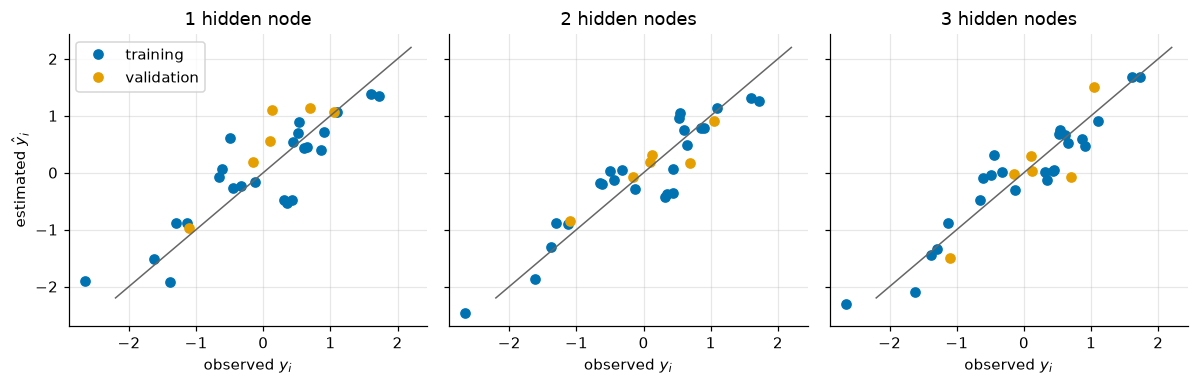

 hidden nodes     period     E    R2   Bias
            1   training 3.036 0.768  0.000
            1 validation 0.741 0.836 -0.393
            2   training 1.965 0.850 -0.000
            2 validation 0.206 0.881  0.012
            3   training 1.327 0.899 -0.000
            3 validation 0.514 0.799  0.079


In [7]:
def ann_fit(H, seed=0, zeta=0.01, epochs=20000):
    """Batch gradient descent on E = 1/2 sum (y_i - y_hat_i)^2. w has shape (3, H): row 0 holds w_0v."""
    r = np.random.default_rng(seed)
    w = r.normal(0, 0.5, (3, H)); alpha = r.normal(0, 0.5, H + 1)
    Xa = np.c_[np.ones(len(train)), X[train][:, [1, 3]]]       # inputs (1, x_2, x_4)
    y_t = y[train]
    for _ in range(epochs):
        h = sigma(Xa @ w)
        e = y_t - (alpha[0] + h @ alpha[1:])
        d = -(e[:, None] * alpha[1:] * h * (1 - h))            # dE/d(argument of sigma)
        alpha[0] -= zeta * (-e.sum())
        alpha[1:] -= zeta * (-(h * e[:, None]).sum(0))
        w -= zeta * (Xa.T @ d)
    return w, alpha

def ann_predict(w, alpha, Xin):
    return alpha[0] + sigma(np.c_[np.ones(len(Xin)), Xin] @ w) @ alpha[1:]

def scores(y_obs, y_est):
    E = 0.5 * np.sum((y_obs - y_est) ** 2)                      # Eq. (5.32)
    bias = np.mean(y_obs - y_est)                               # Eq. (5.35)
    R2 = np.corrcoef(y_obs, y_est)[0, 1] ** 2                   # Eq. (5.36)
    return E, R2, bias

rows = []
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True)
for ax, H in zip(axs, (1, 2, 3)):
    w, alpha = ann_fit(H)
    for name, ix, col in (("training", train, BLUE), ("validation", valid, ORANGE)):
        y_est = ann_predict(w, alpha, X[ix][:, [1, 3]])
        rows.append([H, name, *scores(y[ix], y_est)])
        ax.plot(y[ix], y_est, "o", color=col, label=name)
    ax.plot([-2.2, 2.2], [-2.2, 2.2], color=GREY, lw=1)
    ax.set(title=f"{H} hidden node" + ("s" if H > 1 else ""), xlabel="observed $y_i$")
axs[0].set_ylabel("estimated $\\hat y_i$"); axs[0].legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows, columns=["hidden nodes", "period", "E", "R2", "Bias"]).round(3).to_string(index=False))

Reading the table: as hidden nodes are added, $E$ on the training years falls and $R^2$ rises, because a bigger network has more freedom to follow the training points. On the six validation years the scores do not improve in the same way; the best there is the middle network. So a bigger network fits the years it has seen better but is not necessarily better on new years, which is why the architecture is chosen on the validation period. Six validation years are few, so do not read much into the exact ranking.

**What this means for hydrology:** a network can capture a curved link, but always judge it on years it has not seen; a sigmoid network also levels off outside the range of its training data, so it cannot extrapolate.

# 5.4 Summary

- Too many predictors for too few years lead to overfitting. We choose a few useful predictors.
- **Stepwise regression** adds the predictor with the smallest p-value (below $\alpha_E=0.15$) and removes one whose p-value rises above $\alpha_M=0.15$.
- The **LASSO** minimises squared error plus $\lambda\sum|\beta_j|$ (Eq. 5.20). The soft-threshold rule shrinks each coefficient by the penalty and sets weak ones exactly to zero. The best $\lambda$ is the one with the smallest validation error.
- A **neural network** with sigmoid hidden nodes (Eq. 5.31) can follow curved relations. It is trained by small gradient-descent steps (Eq. 5.34) and compared on validation years with $E$, $R^2$ and bias.
- A bigger model fits the calibration years better but may predict new years no better.

# Check your understanding

1. In the hand example, why is $\hat\beta_1=0$ for $\lambda=12$ but not for $\lambda=6$? For which $\lambda$ does the slope first become zero?
2. In the stepwise printout, why does the procedure stop once $x_4$ and $x_2$ are in?
3. A network with 2 inputs and 3 hidden nodes has how many weights $w_{uv}$ (including offsets) and $\alpha_v$ (including $\alpha_0$)? Why can a long record support more hidden nodes than a short one?

# Try it yourself

- Change `p_wanted` to 1 or 3 and note which predictors the LASSO keeps.
- Change the seed in `ann_fit` and see whether the best number of hidden nodes changes.
- Set $\alpha_E=\alpha_M=0.05$ in the stepwise code and see whether the final model changes.

# Companion spreadsheet

The workbook `data/downscaling/lec20/lec20_worked_examples.xlsx` (blue cells are inputs, black cells are formulas) has four sheets.

| Sheet | What it shows |
|:--|:--|
| `README` | what each sheet does and the colour code |
| `Data` | the 30 standardised years used in this notebook |
| `LASSO_1D` | the by-hand LASSO problem with live formulas, and a table of $\hat\beta_1$ and the total cost for $\lambda=0$ to 14 |
| `Network_1H` | the by-hand network problem: forward pass, gradients and three gradient-descent steps |

```{note} Where this lecture differs from the book
- Eq. (5.28) is printed with garbled signs; we use the soft threshold $(\rho_i\pm\lambda/2)/z_i$ that follows from Eq. (5.27) and the book's Example 5.5.
- The text says the response vector has $S$ elements; it has $n$ (one per case).
- Example 5.5 says the LASSO is fitted by gradient descent; the procedure it follows is coordinate descent (Eqs. 5.23 to 5.28).
- Eq. (5.36) is a squared correlation, which we call $R^2$ as the book does; it is not $1-\mathrm{SSE}/\mathrm{SST}$.
```

```{note} Sources
The methods and notation follow Chapter 5 of Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press: Section 5.2 (stepwise regression and LASSO, Eqs. 5.17 to 5.28, Examples 5.4 and 5.5), Section 5.3 (artificial neural network, Eqs. 5.29 to 5.36, Example 5.6) and Section 5.4. The LASSO is due to Tibshirani, R. (1996), *Journal of the Royal Statistical Society B*, 58(1), 267-288.

All data in this notebook and in the companion workbook are synthetic and the explanations, code and figures are our own. Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```